# 16 · 完整三Session：SWLDA与epoch拒绝策略

固定纳入F03、F05、F06、F07、F08、F20、F21、F23、F24、F25的SE001–SE003全部Train/CBCol EDF，共90份。每个被试×Session独立训练，Session内按EDF文件名与字符顺序取前2/3完整字符训练，其余验证。文件名顺序作为跨文件采集顺序代理，不推断未知的现实暂停。三策略复用同一划分；不读取最终Test。

A：基础故障与技术检查；B：A＋任一16通道PTP>150µV；C：A＋固定old_candidate_overlap_v1旧候选区间重叠拒绝。C保留原25µV额区幅值及其配套规则，不混用新版主波、恢复区间或局部突出度方案。滤波保持60Hz notch→0.5–30Hz因果滤波，逐EDF连续保留状态。


In [4]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/swlda_all_studyf.json').exists())
OUT=ROOT/'outputs/swlda_all_studyf_v3'
cfg=json.loads((OUT/'config_snapshot.json').read_text())
record=json.loads((OUT/'implementation_record.json').read_text())
models=pd.read_csv(OUT/'model_summary.csv')
pred=pd.read_csv(OUT/'character_predictions.csv')
split=pd.read_csv(OUT/'character_split.csv')
overall=pd.read_csv(OUT/'overall_character_summary.csv')
sessions=pd.read_csv(OUT/'session_character_summary.csv')
ret=pd.read_csv(OUT/'validation_retention.csv')
auc=pd.read_csv(OUT/'validation_auc.csv')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
display(pd.Series(record).to_frame('implementation'))


,implementation
classifier,"SWLDA, project-owned OLS forward/backward step..."
implementation_file,src/bigp3bci_swlda.py
implementation_sha256,03867b6ca5a91c0d5711d82683b3705082ba97dc7d1bf0...
reference,https://www.bci2000.org/mediawiki/index.php/Us...
source_config_sha256,673d89a2bdca40c33dc50eb6c2fc9ad4b19857c2113cad...
split_sha256,c4c400aa6964ee223bb1eb7855cee57aa25a6583b97d70...
feature_count,256
models,90
training_characters,360
validation_characters,180


## 1. 数据覆盖、校准预算与划分

先固定完整字符划分，再筛选epoch。每个Session有3份EDF；拒绝后不会追加字符来补足训练epoch。校准预算按实际采集字符和记录时长统计，跨EDF未知间隔不计作已知时长。观察到的非126次flash字符原样保留，不为符合预期改数量。


In [5]:
manifest=pd.read_csv(ROOT/'outputs/studyf_all_preprocessing/selection_manifest.csv')
coverage=manifest.groupby(['subject_id','session_id']).size().unstack()
display(coverage)
assert coverage.shape==(10,3) and coverage.eq(3).all().all()
display(pd.read_csv(OUT/'character_inventory_and_split.csv'))
display(pd.read_csv(OUT/'calibration_and_retention.csv'))


session_id,SE001,SE002,SE003
subject_id,,,
F_03,3,3,3
F_05,3,3,3
F_06,3,3,3
F_07,3,3,3
F_08,3,3,3
F_20,3,3,3
F_21,3,3,3
F_23,3,3,3
F_24,3,3,3


,subject_id,session_id,set,character_trials,flashes
0,F_03,SE001,train,12,1512
1,F_03,SE001,validation,6,756
2,F_03,SE002,train,12,1512
3,F_03,SE002,validation,6,756
4,F_03,SE003,train,12,1512
5,F_03,SE003,validation,6,756
6,F_05,SE001,train,12,1512
7,F_05,SE001,validation,6,756
8,F_05,SE002,train,12,1512
9,F_05,SE002,validation,6,756


,model_id,policy,subject_id,session_id,site,fit_status,n_selected,training_characters,validation_characters,training_epochs,training_target_epochs,fit_cpu_wall_seconds,acquired_calibration_seconds,training_collected_flashes,validation_collected_flashes,training_kept_epochs,validation_kept_epochs
0,F_03_SE001,A,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.058305,423.125,1512,756,1468,734
1,F_03_SE001,B,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.059480,423.125,1512,756,1468,734
2,F_03_SE001,C,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.062744,423.125,1512,756,1468,734
3,F_03_SE002,A,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.049152,423.125,1512,756,1468,734
4,F_03_SE002,B,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.050924,423.125,1512,756,1468,734
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,F_25_SE002,B,F_25,SE002,ETSU,converged,50,12,6,1468,163,0.044690,423.125,1512,756,1468,734
86,F_25_SE002,C,F_25,SE002,ETSU,converged,53,12,6,1221,125,0.046740,423.125,1512,756,1221,437
87,F_25_SE003,A,F_25,SE003,ETSU,converged,39,12,6,1468,163,0.031637,423.125,1512,756,1468,734
88,F_25_SE003,B,F_25,SE003,ETSU,converged,19,12,6,1458,162,0.017443,423.125,1512,756,1458,726


## 2. 映射与训练／验证边界核验

字符预测使用每次flash实际亮起的36个字符状态通道；StimulusCode不当字符编号。CurrentTarget仅用于真值和映射核验，不输入字符预测。集合边界检查共享原始样本以及训练策略确认是否进入验证期。连续因果滤波可使用历史状态，不使用未来验证样本拟合训练参数。


In [6]:
mapping=pd.read_csv(OUT/'mapping_audit.csv')
leak=pd.read_csv(OUT/'split_leakage_audit.csv')
display(mapping)
display(leak)
assert mapping.target_membership_label_disagreements.eq(0).all()
assert not leak.shared_raw_samples.any()
assert not leak.training_confirmation_enters_validation.any()


,edf_name,subject_id,session_id,n_flashes,n_character_state_channels,target_membership_label_disagreements,source_truth,prediction_mapping,true_ids_observed
0,F_03_SE001_CBCol_Train01.edf,F_03,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[5, 6, 18, 20, 21]"
1,F_03_SE001_CBCol_Train02.edf,F_03,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[3, 4, 5, 9, 22]"
2,F_03_SE001_CBCol_Train03.edf,F_03,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[4, 5, 7, 18]"
3,F_03_SE002_CBCol_Train01.edf,F_03,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 4, 7, 9, 14]"
4,F_03_SE002_CBCol_Train02.edf,F_03,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[4, 5, 15, 18, 19]"
...,...,...,...,...,...,...,...,...,...
85,F_25_SE002_CBCol_Train02.edf,F_25,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[7, 8, 9, 11, 14, 20]"
86,F_25_SE002_CBCol_Train03.edf,F_25,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 2, 3, 11, 16, 21]"
87,F_25_SE003_CBCol_Train01.edf,F_25,SE003,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 3, 11, 20]"
88,F_25_SE003_CBCol_Train02.edf,F_25,SE003,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 2, 7, 12, 15]"


,edf_name,model_id,policy,raw_sample_gap,training_policy_to_first_validation_seconds,shared_raw_samples,training_confirmation_enters_validation,scope,train_edfs,validation_edfs
0,NaN,F_03_SE001,A,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE001_CBCol_Train01.edf;F_03_SE001_CBCol_...,F_03_SE001_CBCol_Train03.edf
1,NaN,F_03_SE001,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE001_CBCol_Train01.edf;F_03_SE001_CBCol_...,F_03_SE001_CBCol_Train03.edf
2,NaN,F_03_SE001,C,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE001_CBCol_Train01.edf;F_03_SE001_CBCol_...,F_03_SE001_CBCol_Train03.edf
3,NaN,F_03_SE002,A,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE002_CBCol_Train01.edf;F_03_SE002_CBCol_...,F_03_SE002_CBCol_Train03.edf
4,NaN,F_03_SE002,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE002_CBCol_Train01.edf;F_03_SE002_CBCol_...,F_03_SE002_CBCol_Train03.edf
...,...,...,...,...,...,...,...,...,...,...
85,NaN,F_25_SE002,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_25_SE002_CBCol_Train01.edf;F_25_SE002_CBCol_...,F_25_SE002_CBCol_Train03.edf
86,NaN,F_25_SE002,C,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_25_SE002_CBCol_Train01.edf;F_25_SE002_CBCol_...,F_25_SE002_CBCol_Train03.edf
87,NaN,F_25_SE003,A,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_25_SE003_CBCol_Train01.edf;F_25_SE003_CBCol_...,F_25_SE003_CBCol_Train03.edf
88,NaN,F_25_SE003,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_25_SE003_CBCol_Train01.edf;F_25_SE003_CBCol_...,F_25_SE003_CBCol_Train03.edf


## 3. 固定特征与SWLDA

16通道×16个50ms平均电压窗＝256维；0–800ms，baseline=None。256Hz下205点，按整数样本时间归入相邻半开窗。各模型只在自己的保留训练epoch上估计标准化参数及筛选特征。

沿用项目内前向／后向逐步OLS SWLDA：进入p<0.10，移除p>0.15，最多60特征；不替换成普通LDA。参考[BCI2000 P300Classifier](https://www.bci2000.org/mediawiki/index.php/User_Reference:P300Classifier)，不声称逐位复现。选中特征、权重和选择过程保存在models子目录。


In [7]:
display(pd.Series(cfg['swlda']).to_frame('SWLDA settings'))
display(pd.read_csv(OUT/'feature_dictionary.csv').head(18))
display(models)
assert len(models)==90 and models.fit_status.isin(['converged','max_features_reached']).all()
assert models.n_selected.le(60).all()


,SWLDA settings
implementation,project-owned forward/backward OLS stepwise li...
p_enter,0.1
p_remove,0.15
max_features,60
max_steps,500
rank_tolerance,0.0
standardize,"training retained epochs only, population std;..."
class_weighting,None
reference,https://www.bci2000.org/mediawiki/index.php/Us...
reproduction_limit,classic stepwise SWLDA algorithm on requested ...


,feature_index,channel,bin_index,start_ms,end_ms
0,0,EEG_F3,0,0,50
1,1,EEG_F3,1,50,100
2,2,EEG_F3,2,100,150
3,3,EEG_F3,3,150,200
4,4,EEG_F3,4,200,250
5,5,EEG_F3,5,250,300
6,6,EEG_F3,6,300,350
7,7,EEG_F3,7,350,400
8,8,EEG_F3,8,400,450
9,9,EEG_F3,9,450,500


,model_id,policy,subject_id,session_id,site,fit_status,n_selected,training_characters,validation_characters,training_epochs,training_target_epochs,fit_cpu_wall_seconds,acquired_calibration_seconds
0,F_03_SE001,A,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.058305,423.125
1,F_03_SE001,B,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.059480,423.125
2,F_03_SE001,C,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.062744,423.125
3,F_03_SE002,A,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.049152,423.125
4,F_03_SE002,B,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.050924,423.125
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,F_25_SE002,B,F_25,SE002,ETSU,converged,50,12,6,1468,163,0.044690,423.125
86,F_25_SE002,C,F_25,SE002,ETSU,converged,53,12,6,1221,125,0.046740,423.125
87,F_25_SE003,A,F_25,SE003,ETSU,converged,39,12,6,1468,163,0.031637,423.125
88,F_25_SE003,B,F_25,SE003,ETSU,converged,19,12,6,1458,162,0.017443,423.125


## 4. 总体与配对字符结果

同一组验证字符保留在三策略分母中，无输出计为错误。拒绝flash的分数为空，不填0。字符证据为“亮起时平均target分数－未亮起时平均分数”；36个候选均须有亮起和未亮起证据，否则无输出。此规则未依据结果调整。


In [8]:
display(overall)
validation_ret=ret.groupby('policy',as_index=False)[['collected','kept']].sum()
validation_ret['retention']=validation_ret.kept/validation_ret.collected
display(validation_ret)
display(pd.read_csv(OUT/'paired_strategy_summary.csv'))
display(pd.read_csv(OUT/'paired_character_comparison.csv'))
summary=overall.set_index('policy')
display(Markdown('本轮字符准确率：'+ '；'.join(f"{p}为{int(summary.loc[p,'correct_characters'])}/{int(summary.loc[p,'validation_characters'])}（{summary.loc[p,'character_accuracy']:.2%}），无输出{int(summary.loc[p,'no_output_characters'])}个" for p in ['A','B','C'])+'。无输出均保留在总分母中。'))


,policy,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters
0,A,180,142,0.788889,180,0.00000,0.00000,122.016667,0
1,B,180,138,0.766667,179,0.00000,0.00000,119.072222,1
2,C,180,124,0.688889,174,1.34375,1.34375,105.244444,6


,policy,collected,kept,retention
0,A,22680,21963,0.968386
1,B,22680,21433,0.945018
2,C,22680,18944,0.835273


,first,second,characters,second_only_correct,first_only_correct,accuracy_difference,paired_exact_binomial_p,mean_extra_wait_seconds,note
0,A,B,180,1,5,-0.022222,0.218750,0.00000,descriptive paired development comparison; no ...
1,A,C,180,3,21,-0.100000,0.000277,1.34375,descriptive paired development comparison; no ...
2,B,C,180,7,21,-0.077778,0.012541,1.34375,descriptive paired development comparison; no ...


,model_id,edf_name,character_key,true_character,correct_A,correct_B,correct_C,predicted_character_A,predicted_character_B,predicted_character_C,...,output_available_C,valid_flashes_A,valid_flashes_B,valid_flashes_C,prediction_available_seconds_A,prediction_available_seconds_B,prediction_available_seconds_C,evidence_ready_seconds_A,evidence_ready_seconds_B,evidence_ready_seconds_C
0,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,D_1_4,True,True,True,D_1_4,D_1_4,D_1_4,...,True,104,104,104,36.5625,36.5625,37.90625,36.5625,36.5625,37.90625
1,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T02,E_1_5,True,True,True,E_1_5,E_1_5,E_1_5,...,True,126,126,126,71.5625,71.5625,72.90625,71.5625,71.5625,72.90625
2,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T03,G_2_1,True,True,True,G_2_1,G_2_1,G_2_1,...,True,126,126,126,106.5625,106.5625,107.90625,106.5625,106.5625,107.90625
3,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T04,R_3_6,True,True,True,R_3_6,R_3_6,R_3_6,...,True,126,126,126,141.5625,141.5625,142.90625,141.5625,141.5625,142.90625
4,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T05,E_1_5,True,True,True,E_1_5,E_1_5,E_1_5,...,True,126,126,126,176.5625,176.5625,177.90625,176.5625,176.5625,177.90625
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T02,I_2_3,True,False,False,I_2_3,Z_5_2,J_2_4,...,True,126,121,63,71.5625,71.5625,72.90625,71.5625,71.5625,72.90625
176,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T03,S_4_1,True,True,True,S_4_1,S_4_1,S_4_1,...,True,126,123,105,106.5625,106.5625,107.90625,106.5625,106.5625,107.90625
177,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T04,U_4_3,False,True,False,A_1_1,U_4_3,Sp_5_3,...,True,126,126,94,141.5625,141.5625,142.90625,141.5625,141.5625,142.90625
178,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T05,A_1_1,True,True,True,A_1_1,A_1_1,A_1_1,...,True,126,126,112,176.5625,176.5625,177.90625,176.5625,176.5625,177.90625


本轮字符准确率：A为142/180（78.89%），无输出0个；B为138/180（76.67%），无输出1个；C为124/180（68.89%），无输出6个。无输出均保留在总分母中。

## 5. 十人合并误差线图：完整三Session

左右分别为字符准确率与验证epoch保留率；点为3个Session的等权均值，误差线为±1个Session间样本标准差，不是置信区间。误差线可能超出0–100%，不截短。下方按字符数汇总的表与此均值在各Session分母不同时可能不同。


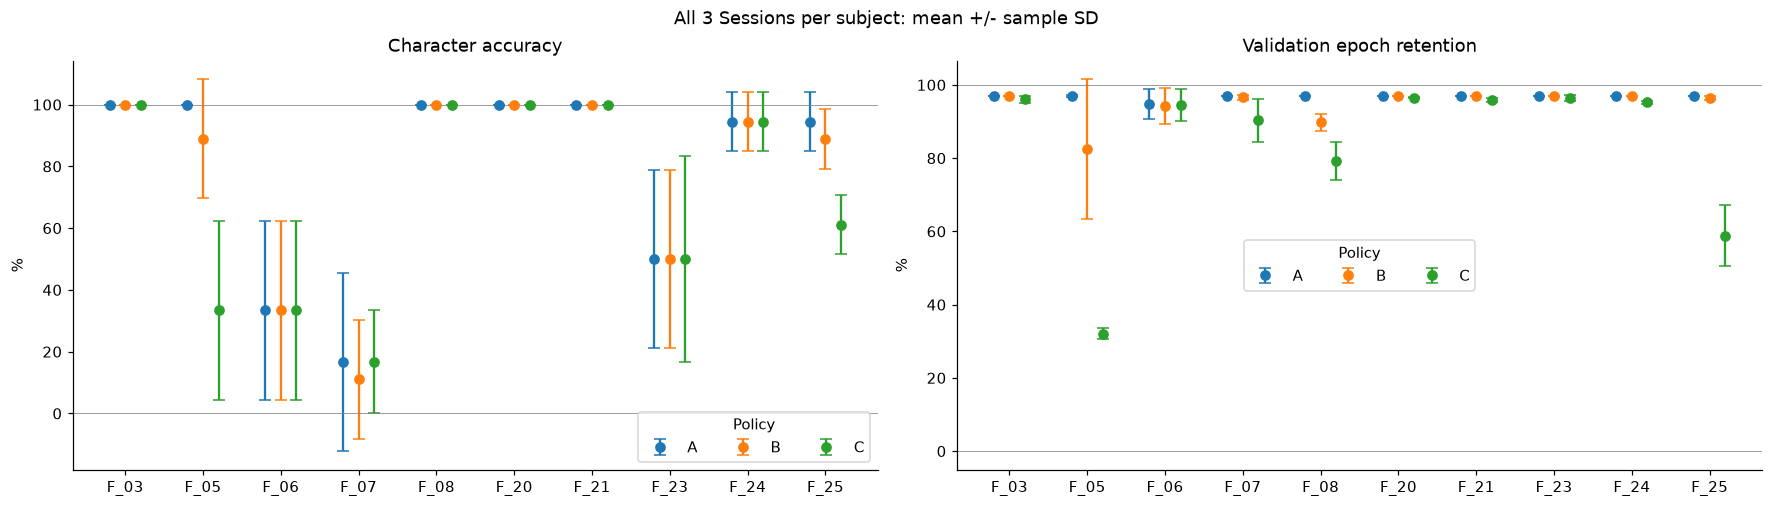

,policy,subject_id,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters
0,A,F_03,18,18,1.000000,18,0.00000,0.00000,122.333333,0
1,A,F_05,18,18,1.000000,18,0.00000,0.00000,122.111111,0
2,A,F_06,18,6,0.333333,18,0.00000,0.00000,119.388889,0
3,A,F_07,18,3,0.166667,18,0.00000,0.00000,122.333333,0
4,A,F_08,18,18,1.000000,18,0.00000,0.00000,122.333333,0
5,A,F_20,18,18,1.000000,18,0.00000,0.00000,122.333333,0
6,A,F_21,18,18,1.000000,18,0.00000,0.00000,122.333333,0
7,A,F_23,18,9,0.500000,18,0.00000,0.00000,122.333333,0
8,A,F_24,18,17,0.944444,18,0.00000,0.00000,122.333333,0
9,A,F_25,18,17,0.944444,18,0.00000,0.00000,122.333333,0


,policy,subject_id,session_id,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters,collected,kept,retention,scored
0,A,F_03,SE001,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
1,A,F_03,SE002,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
2,A,F_03,SE003,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
3,A,F_05,SE001,6,6,1.000000,6,0.00000,0.00000,121.666667,0,756,730,0.965608,730
4,A,F_05,SE002,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,C,F_24,SE002,6,5,0.833333,6,1.34375,1.34375,120.333333,0,756,722,0.955026,722
86,C,F_24,SE003,6,6,1.000000,6,1.34375,1.34375,119.333333,0,756,716,0.947090,716
87,C,F_25,SE001,6,3,0.500000,6,1.34375,1.34375,64.333333,0,756,386,0.510582,386
88,C,F_25,SE002,6,4,0.666667,6,1.34375,1.34375,72.833333,0,756,437,0.578042,437


In [9]:
session_metrics=sessions.merge(ret,on=['policy','subject_id','session_id'],validate='one_to_one')
subjects=sorted(sessions.subject_id.unique())
fig,axes=plt.subplots(1,2,figsize=(16,4.5),layout='constrained')
rows=[]
for ax,metric,title in zip(axes,['character_accuracy','retention'],['Character accuracy','Validation epoch retention']):
    for j,policy in enumerate(['A','B','C']):
        q=session_metrics.loc[session_metrics.policy.eq(policy)].groupby('subject_id')[metric].agg(['mean','std','count']).reindex(subjects)
        assert q['count'].eq(3).all()
        ax.errorbar(np.arange(len(subjects))+(j-1)*.2,q['mean']*100,yerr=q['std']*100,fmt='o',capsize=4,label=policy)
        for subject,r in q.iterrows():
            rows.append(dict(subject_id=subject,policy=policy,metric=metric,session_mean=r['mean'],session_sd=r['std'],n_sessions=int(r['count'])))
    ax.set(xticks=range(len(subjects)),xticklabels=subjects,ylabel='%',title=title)
    ax.axhline(0,color='grey',lw=.5);ax.axhline(100,color='grey',lw=.5)
    ax.legend(title='Policy',ncol=3)
fig.suptitle('All 3 Sessions per subject: mean +/- sample SD')
fig.savefig(OUT/'subject_model_errorbars.png',dpi=150)
plt.show()
pd.DataFrame(rows).to_csv(OUT/'subject_model_errorbars.csv',index=False)
display(pd.read_csv(OUT/'subject_character_summary.csv'))
display(session_metrics)


## 6. 每位被试的模型与字符明细

以下仅分开展示表格，不另画六张图。不同Session有独立模型；不会将未校准的模型分数拼成一个ROC。


In [10]:
model_details=models.merge(sessions,on=['model_id'] if 'model_id' in sessions else ['subject_id','session_id','policy','validation_characters'],validate='one_to_one')
for scope,label in [('own_valid_scored_epochs','own_auc'),('common_valid_scored_epochs_A_B_C','common_auc')]:
    model_details=model_details.merge(auc.loc[auc.scope.eq(scope),['model_id','policy','auc']].rename(columns={'auc':label}),on=['model_id','policy'],validate='one_to_one')
model_details.to_csv(OUT/'subject_session_model_results.csv',index=False)
for subject in subjects:
    display(Markdown(f'### {subject}'))
    display(model_details.loc[model_details.subject_id.eq(subject),['model_id','policy','training_characters','training_epochs','n_selected','correct_characters','validation_characters','no_output_characters','own_auc','common_auc']])
    display(pred.loc[pred.subject_id.eq(subject),['session_id','edf_name','character_trial_id','policy','true_character','predicted_character','correct','valid_flashes','prediction_status']].sort_values(['session_id','edf_name','character_trial_id','policy']))


### F_03

,model_id,policy,training_characters,training_epochs,n_selected,correct_characters,validation_characters,no_output_characters,own_auc,common_auc
0,F_03_SE001,A,12,1468,60,6,6,0,0.953737,0.953737
1,F_03_SE001,B,12,1468,60,6,6,0,0.953737,0.953737
2,F_03_SE001,C,12,1468,60,6,6,0,0.953737,0.953737
3,F_03_SE002,A,12,1468,53,6,6,0,0.843968,0.845891
4,F_03_SE002,B,12,1468,53,6,6,0,0.843968,0.845891
5,F_03_SE002,C,12,1457,53,6,6,0,0.843615,0.843615
6,F_03_SE003,A,12,1468,59,6,6,0,0.859244,0.864096
7,F_03_SE003,B,12,1468,59,6,6,0,0.859244,0.864096
8,F_03_SE003,C,12,1464,60,6,6,0,0.870670,0.870670


,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
0,SE001,F_03_SE001_CBCol_Train03.edf,1,A,D_1_4,D_1_4,True,104,predicted
6,SE001,F_03_SE001_CBCol_Train03.edf,1,B,D_1_4,D_1_4,True,104,predicted
12,SE001,F_03_SE001_CBCol_Train03.edf,1,C,D_1_4,D_1_4,True,104,predicted
1,SE001,F_03_SE001_CBCol_Train03.edf,2,A,E_1_5,E_1_5,True,126,predicted
7,SE001,F_03_SE001_CBCol_Train03.edf,2,B,E_1_5,E_1_5,True,126,predicted
13,SE001,F_03_SE001_CBCol_Train03.edf,2,C,E_1_5,E_1_5,True,126,predicted
2,SE001,F_03_SE001_CBCol_Train03.edf,3,A,G_2_1,G_2_1,True,126,predicted
8,SE001,F_03_SE001_CBCol_Train03.edf,3,B,G_2_1,G_2_1,True,126,predicted
14,SE001,F_03_SE001_CBCol_Train03.edf,3,C,G_2_1,G_2_1,True,126,predicted
3,SE001,F_03_SE001_CBCol_Train03.edf,4,A,R_3_6,R_3_6,True,126,predicted


### F_05

,model_id,policy,training_characters,training_epochs,n_selected,correct_characters,validation_characters,no_output_characters,own_auc,common_auc
9,F_05_SE001,A,12,1468,59,6,6,0,0.970152,0.933735
10,F_05_SE001,B,12,1409,60,6,6,0,0.968032,0.920348
11,F_05_SE001,C,12,729,46,1,6,3,0.630522,0.630522
12,F_05_SE002,A,12,1468,54,6,6,0,0.958331,0.876777
13,F_05_SE002,B,12,1130,57,4,6,1,0.885199,0.860190
14,F_05_SE002,C,12,562,21,4,6,1,0.959243,0.890995
15,F_05_SE003,A,12,1464,55,6,6,0,0.978977,0.954506
16,F_05_SE003,B,12,1455,49,6,6,0,0.976324,0.937339
17,F_05_SE003,C,12,524,29,1,6,2,0.612017,0.612017


,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
54,SE001,F_05_SE001_CBCol_Train04.edf,1,A,L_2_6,L_2_6,True,104,predicted
60,SE001,F_05_SE001_CBCol_Train04.edf,1,B,L_2_6,L_2_6,True,104,predicted
66,SE001,F_05_SE001_CBCol_Train04.edf,1,C,L_2_6,R_3_6,False,43,predicted
55,SE001,F_05_SE001_CBCol_Train04.edf,2,A,E_1_5,E_1_5,True,126,predicted
61,SE001,F_05_SE001_CBCol_Train04.edf,2,B,E_1_5,E_1_5,True,113,predicted
67,SE001,F_05_SE001_CBCol_Train04.edf,2,C,E_1_5,NaN,False,40,insufficient_evidence
56,SE001,F_05_SE001_CBCol_Train04.edf,3,A,A_1_1,A_1_1,True,126,predicted
62,SE001,F_05_SE001_CBCol_Train04.edf,3,B,A_1_1,A_1_1,True,115,predicted
68,SE001,F_05_SE001_CBCol_Train04.edf,3,C,A_1_1,A_1_1,True,39,predicted
57,SE001,F_05_SE001_CBCol_Train04.edf,4,A,D_1_4,D_1_4,True,122,predicted


... (20 outputs left out)

,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
432,SE001,F_24_SE001_CBCol_Train03.edf,1,A,U_4_3,U_4_3,True,104,predicted
438,SE001,F_24_SE001_CBCol_Train03.edf,1,B,U_4_3,U_4_3,True,104,predicted
444,SE001,F_24_SE001_CBCol_Train03.edf,1,C,U_4_3,U_4_3,True,98,predicted
433,SE001,F_24_SE001_CBCol_Train03.edf,2,A,S_4_1,S_4_1,True,126,predicted
439,SE001,F_24_SE001_CBCol_Train03.edf,2,B,S_4_1,S_4_1,True,126,predicted
445,SE001,F_24_SE001_CBCol_Train03.edf,2,C,S_4_1,S_4_1,True,126,predicted
434,SE001,F_24_SE001_CBCol_Train03.edf,3,A,E_1_5,E_1_5,True,126,predicted
440,SE001,F_24_SE001_CBCol_Train03.edf,3,B,E_1_5,E_1_5,True,126,predicted
446,SE001,F_24_SE001_CBCol_Train03.edf,3,C,E_1_5,E_1_5,True,126,predicted
435,SE001,F_24_SE001_CBCol_Train03.edf,4,A,F_1_6,F_1_6,True,126,predicted


### F_25

,model_id,policy,training_characters,training_epochs,n_selected,correct_characters,validation_characters,no_output_characters,own_auc,common_auc
81,F_25_SE001,A,12,1468,37,6,6,0,0.773717,0.756186
82,F_25_SE001,B,12,1452,33,5,6,0,0.766937,0.779922
83,F_25_SE001,C,12,792,21,3,6,0,0.713718,0.725928
84,F_25_SE002,A,12,1468,50,6,6,0,0.843722,0.841655
85,F_25_SE002,B,12,1468,50,6,6,0,0.843722,0.841655
86,F_25_SE002,C,12,1221,53,4,6,0,0.853386,0.853386
87,F_25_SE003,A,12,1468,39,5,6,0,0.793431,0.755774
88,F_25_SE003,B,12,1458,19,5,6,0,0.758924,0.717949
89,F_25_SE003,C,12,930,30,4,6,0,0.746829,0.746829


,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
486,SE001,F_25_SE001_CBCol_Train03.edf,1,A,O_3_3,O_3_3,True,104,predicted
492,SE001,F_25_SE001_CBCol_Train03.edf,1,B,O_3_3,O_3_3,True,104,predicted
498,SE001,F_25_SE001_CBCol_Train03.edf,1,C,O_3_3,2_5_5,False,45,predicted
487,SE001,F_25_SE001_CBCol_Train03.edf,2,A,T_4_2,T_4_2,True,126,predicted
493,SE001,F_25_SE001_CBCol_Train03.edf,2,B,T_4_2,F_1_6,False,123,predicted
499,SE001,F_25_SE001_CBCol_Train03.edf,2,C,T_4_2,T_4_2,True,66,predicted
488,SE001,F_25_SE001_CBCol_Train03.edf,3,A,H_2_2,H_2_2,True,126,predicted
494,SE001,F_25_SE001_CBCol_Train03.edf,3,B,H_2_2,H_2_2,True,124,predicted
500,SE001,F_25_SE001_CBCol_Train03.edf,3,C,H_2_2,N_3_2,False,43,predicted
489,SE001,F_25_SE001_CBCol_Train03.edf,4,A,E_1_5,E_1_5,True,126,predicted


## 7. 辅助AUC、等待与证据损失

own为各自保留的验证epoch；common为同一模型组三策略共同有效epoch。总体仅按30个模型组宏平均AUC，不拼接不同模型原始分数。时间按实际样本时钟取max(字符结束、该字符所有flash质量决策完成)，不逐flash累加等待；无输出的prediction_available_seconds为空。

C确认等待包括排除未来才确认的旧眨眼候选的保守等待。这里是回放数据可用时刻，未测量设备通信和逐epoch实机计算延迟。


In [11]:
display(pd.read_csv(OUT/'overall_macro_auc.csv'))
display(auc)
display(overall[['policy','mean_valid_flashes','no_output_characters','mean_decision_wait_after_trial_seconds','mean_output_wait_after_trial_seconds']])
display(pd.read_csv(OUT/'stimulus_group_flash_counts.csv').head(24))
display(pred[['policy','character_key','trial_end_seconds','evidence_ready_seconds','prediction_available_seconds']].head(18))


,policy,scope,model_folds,macro_auc
0,A,common_valid_scored_epochs_A_B_C,30,0.814291
1,A,own_valid_scored_epochs,30,0.819695
2,B,common_valid_scored_epochs_A_B_C,30,0.809608
3,B,own_valid_scored_epochs,30,0.814027
4,C,common_valid_scored_epochs_A_B_C,30,0.791948
5,C,own_valid_scored_epochs,30,0.793371


,model_id,policy,subject_id,session_id,site,scope,n_epochs,auc
0,F_03_SE001,A,F_03,SE001,ETSU,own_valid_scored_epochs,734,0.953737
1,F_03_SE001,B,F_03,SE001,ETSU,own_valid_scored_epochs,734,0.953737
2,F_03_SE001,C,F_03,SE001,ETSU,own_valid_scored_epochs,734,0.953737
3,F_03_SE001,A,F_03,SE001,ETSU,common_valid_scored_epochs_A_B_C,734,0.953737
4,F_03_SE001,B,F_03,SE001,ETSU,common_valid_scored_epochs_A_B_C,734,0.953737
...,...,...,...,...,...,...,...,...
175,F_25_SE003,B,F_25,SE003,ETSU,own_valid_scored_epochs,726,0.758924
176,F_25_SE003,C,F_25,SE003,ETSU,own_valid_scored_epochs,512,0.746829
177,F_25_SE003,A,F_25,SE003,ETSU,common_valid_scored_epochs_A_B_C,512,0.755774
178,F_25_SE003,B,F_25,SE003,ETSU,common_valid_scored_epochs_A_B_C,512,0.717949


,policy,mean_valid_flashes,no_output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds
0,A,122.016667,0,0.00000,0.00000
1,B,119.072222,1,0.00000,0.00000
2,C,105.244444,6,1.34375,1.34375


,model_id,policy,edf_name,character_key,stimulus_group_id,total_flashes,valid_flashes,scored_flashes
0,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_0312288a214b,1,0,0
1,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_06cc9cb80ee0,1,1,1
2,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_0b2959d0085f,1,1,1
3,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_105ac5f38689,1,1,1
4,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_106d3f6ec43f,1,1,1
5,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_123508c1928c,1,1,1
6,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_13a757b5535a,1,1,1
7,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_14ebf4bf52de,1,1,1
8,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_1629ba64cacc,1,1,1
9,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_1688d2cc969d,1,1,1


,policy,character_key,trial_end_seconds,evidence_ready_seconds,prediction_available_seconds
0,A,F_03_SE001_CBCol_Train03_T01,36.5625,36.56250,36.56250
1,A,F_03_SE001_CBCol_Train03_T02,71.5625,71.56250,71.56250
2,A,F_03_SE001_CBCol_Train03_T03,106.5625,106.56250,106.56250
3,A,F_03_SE001_CBCol_Train03_T04,141.5625,141.56250,141.56250
4,A,F_03_SE001_CBCol_Train03_T05,176.5625,176.56250,176.56250
5,A,F_03_SE001_CBCol_Train03_T06,211.5625,211.56250,211.56250
6,B,F_03_SE001_CBCol_Train03_T01,36.5625,36.56250,36.56250
7,B,F_03_SE001_CBCol_Train03_T02,71.5625,71.56250,71.56250
8,B,F_03_SE001_CBCol_Train03_T03,106.5625,106.56250,106.56250
9,B,F_03_SE001_CBCol_Train03_T04,141.5625,141.56250,141.56250


## 8. 全部StudyF结果与复现

本轮覆盖本地全部StudyF的10人、30个Session和90份Train EDF，不纳入StudyB或最终Test。A/B/C评价同一组验证字符，无输出计入总分母。比较准确率的变化、证据损失和确认等待，并检查各被试是否一致，不根据本轮结果修改检测参数。

预处理、特征及SWLDA参数与前轮一致。新增被试按完整清单纳入，没有按检测或分类表现挑选。每Session12个字符训练、6个验证；这与六人完整版具有相同校准预算，但比最初pilot预算更大。既有Train数据曾用于开发，本轮仍不是独立最终测试。站点映射沿用项目推断，保持inferred。

复现：run_all_studyf_preprocessing.py；run_swlda_rejection_experiment.py --config configs/swlda_all_studyf.json --output outputs/swlda_all_studyf_v3；audit_swlda_saved_experiment.py outputs/swlda_all_studyf_v3；build_three_session_experiment_notebook.py --all-studyf，然后运行本notebook。旧v1/v2结果均保留。


In [12]:
scores=pd.read_csv(OUT/'epoch_scores.csv',low_memory=False)
label_retention=scores.loc[scores.set.eq('validation')].groupby(['subject_id','session_id','policy','label']).agg(total=('would_keep','size'),kept=('would_keep','sum'),retention=('would_keep','mean')).reset_index()
label_retention.to_csv(OUT/'validation_label_retention.csv',index=False)
display(label_retention)
triggers=scores.loc[scores.set.eq('validation') & ~scores.would_keep,['subject_id','session_id','policy','trigger_channels']].copy()
triggers['channel']=triggers.trigger_channels.fillna('').str.split(';')
triggers=triggers.explode('channel')
trigger_summary=triggers.loc[triggers.channel.ne('')].groupby(['subject_id','session_id','policy','channel']).size().rename('triggered_epochs').reset_index()
trigger_summary.to_csv(OUT/'validation_trigger_channels.csv',index=False)
display(trigger_summary.sort_values('triggered_epochs',ascending=False).head(24))
assert scores.loc[~scores.would_keep,'target_score'].isna().all()
assert not scores.loc[~scores.would_keep,'has_score'].any()
n_validation=split.set.eq('validation').sum()
assert pred.groupby('policy').size().eq(n_validation).all()
assert pred.groupby('character_key').policy.nunique().eq(3).all()
assert pred.loc[~pred.output_available,'prediction_available_seconds'].isna().all()
assert not pred.loc[~pred.output_available,'correct'].any()
assert not record['used_final_test_data']
assert cfg['blink_interval_version']=='old_candidate_overlap_v1'
print('PASS: 90 EDFs, all 30 subject/Session groups; identical validation characters; no zero-filled rejected scores; no final Test')


,subject_id,session_id,policy,label,total,kept,retention
0,F_03,SE001,A,non-target,672,653,0.971726
1,F_03,SE001,A,target,84,81,0.964286
2,F_03,SE001,B,non-target,672,653,0.971726
3,F_03,SE001,B,target,84,81,0.964286
4,F_03,SE001,C,non-target,672,653,0.971726
...,...,...,...,...,...,...,...
175,F_25,SE003,A,target,84,82,0.976190
176,F_25,SE003,B,non-target,672,645,0.959821
177,F_25,SE003,B,target,84,81,0.964286
178,F_25,SE003,C,non-target,672,455,0.677083


,subject_id,session_id,policy,channel,triggered_epochs
7,F_05,SE002,B,EEG_F3,272
8,F_05,SE002,B,EEG_F4,210
19,F_08,SE001,B,EEG_F3,76
20,F_08,SE001,B,EEG_F4,65
21,F_08,SE001,B,EEG_Fz,59
9,F_05,SE002,B,EEG_Fz,55
2,F_05,SE001,B,EEG_F4,54
15,F_06,SE001,C,EEG_Oz,53
14,F_06,SE001,B,EEG_Oz,53
12,F_06,SE001,A,EEG_Oz,53


PASS: 90 EDFs, all 30 subject/Session groups; identical validation characters; no zero-filled rejected scores; no final Test


In [13]:
display(Markdown('### 三策略配对结论'))
comparison=pd.read_csv(OUT/'paired_strategy_summary.csv')
for row in comparison.itertuples():
    display(Markdown(f'{row.first}→{row.second}：新增正确{row.second_only_correct}个，损失{row.first_only_correct}个；准确率变化{row.accuracy_difference*100:+.2f}个百分点，平均额外等待{row.mean_extra_wait_seconds:.3f}秒。'))
display(models.groupby('fit_status').size().rename('models').to_frame())
display(pd.read_csv(OUT/'model_training_only_audit.csv'))
print('All StudyF Train files included; no StudyB and no final Test; no detector retuning.')


### 三策略配对结论

A→B：新增正确1个，损失5个；准确率变化-2.22个百分点，平均额外等待0.000秒。

A→C：新增正确3个，损失21个；准确率变化-10.00个百分点，平均额外等待1.344秒。

B→C：新增正确7个，损失21个；准确率变化-7.78个百分点，平均额外等待1.344秒。

,models
fit_status,
converged,67
max_features_reached,23


,model_id,policy,training_epochs,n_selected,max_final_selected_p,train_only_scaling_verified,saved_scores_verified
0,F_03_SE001,A,1468,60,0.146861,True,True
1,F_03_SE001,B,1468,60,0.146861,True,True
2,F_03_SE001,C,1468,60,0.146861,True,True
3,F_03_SE002,A,1468,53,0.143227,True,True
4,F_03_SE002,B,1468,53,0.143227,True,True
...,...,...,...,...,...,...,...
85,F_25_SE002,B,1468,50,0.091803,True,True
86,F_25_SE002,C,1221,53,0.095731,True,True
87,F_25_SE003,A,1468,39,0.087941,True,True
88,F_25_SE003,B,1458,19,0.137615,True,True


All StudyF Train files included; no StudyB and no final Test; no detector retuning.
